# Changing codes, level by level: the fold-transversal Hadamard

This notebook follows Section 4.1 of the paper step by step. Each step has a few lines on **what we do**, then the code (library calls only; the program and its layout come from the example modules `interactive_fold_h_3d.py` and `interactive_fold_h_gpf_3d.py`), then **what you see**. Every figure of the section is made here (saved to `figures/fth-*.pdf`), and every number is printed here.

> **In short.**
> * **The protocol.** A Hadamard on every qubit of the surface code is a logical Hadamard, but it swaps the X checks and the Z checks: the qubits end up in a different code. A quarter turn of the grid brings the code back.
> * **The levels.** The same program, read four ways. Each level is a list of blocks, and the tool answers the three questions (which code, what it does, in every run?) for each block.

| level | blocks | what the tool says |
|---|---|---|
| 0 | the eight stages: the physical gates | each stage alone is I (or H for the Hadamards), in every run |
| 1 | the protocol's six pieces, each with the role it should play | every block plays its role; the code changes after the Hadamards and comes back after the turn |
| 2 | the Hadamards, a round of checks and the turn as one block | a logical H that starts and ends in the surface code, with qubits matched by their place on the chip |
| 3 | the whole program | H, followed by Paulis that the results determine |

With a check wired to the wrong qubit, levels 1 and 2 report a problem; level 0 shows where the code breaks ([[9,1,1]] after stage 5); level 3 still says H.

In [1]:
%matplotlib inline
import os
from collections import Counter
import matplotlib
import pyzx as zx
from IPython.display import display
from pyzx.circuit.gates import Measurement
import interactive_fold_h_3d as fth          # build_program: the program's OpenQASM files as a QProgram
import interactive_fold_h_gpf_3d as gpf      # the same program with each stage a block of its own, rewritten
matplotlib.use('module://matplotlib_inline.backend_inline', force=True)   # the modules ask for a window backend
from zxqec.gpf import layout_gpf, phases_modulo
from zxqec.spacetime import (block_spans, draw_blocks_3d, draw_graph, draw_program, draw_program_3d, save_panels,
                             view_levels_3d)
os.makedirs('figures', exist_ok=True)

## Level 0: the physical gates

**What we do.** `build_program` reads the program's seven OpenQASM files and adds the quarter turn as a permutation of the qubits over the chip (`add_permutation`, no gates): eight stages on 19 qubits. Qubit 0 is the input, 1 to 9 the $3 \times 3$ grid, 10 to 17 the ancillas that measure the checks, 18 the output. Level 0 has one block per stage. We list what each stage does and which results it writes.

In [2]:
p = fth.build_program()
print(p.describe_level(0))
written = set()
for s in range(p.num_stages):
    n = Counter(type(g).__name__ for g in p.stage_circuit(s).gates)
    bits = [g.result_symbol for g in p.stage_circuit(s).gates if isinstance(g, Measurement)]
    written |= set(bits)
    print("stage {} {:18s} {:11s} {:2d} CNOT {:2d} H {:2d} resets {:2d} measurements {}".format(
        s, str(p.stage(s)), p.stage(s).kind, n['CNOT'], n['HAD'], n['Reset'], n['Measurement'], ' '.join(bits)))
print("qubits:", p.qubits, "; results written:", len(written), "of the register's", p.bits,
      "bits; never written:", [c for c in ('c[{}]'.format(b) for b in range(p.bits)) if c not in written])
whole = p.quantum_graph()
print("the whole program:", sum(1 for v in whole.vertices() if whole.type(v) != 0), "spiders")

Level 0 (8 blocks):
  Block 0 'encode + X checks': [encode + X checks]
  Block 1 'transversal H': [transversal H]
  Block 2 'Z checks (code 2)': [Z checks (code 2)]
  Block 3 'X checks (code 2)': [X checks (code 2)]
  Block 4 'rotate 90°': [rotate 90°]
  Block 5 'Z checks': [Z checks]
  Block 6 'X checks': [X checks]
  Block 7 'Z checks + decode': [Z checks + decode]
stage 0 encode + X checks  circuit     15 CNOT  5 H  0 resets  5 measurements c[0] c[1] c[2] c[3] c[4]
stage 1 transversal H      circuit      0 CNOT  9 H  0 resets  0 measurements 
stage 2 Z checks (code 2)  circuit     12 CNOT  0 H  4 resets  4 measurements c[6] c[5] c[7] c[8]
stage 3 X checks (code 2)  circuit     12 CNOT  4 H  0 resets  4 measurements c[9] c[10] c[11] c[12]
stage 4 rotate 90°         permutation  0 CNOT  0 H  0 resets  0 measurements 
stage 5 Z checks           circuit     12 CNOT  0 H  4 resets  4 measurements c[13] c[14] c[15] c[16]
stage 6 X checks           circuit     12 CNOT  8 H  4 resets  4 mea

**What we do next.** `summary(0)` answers the three questions for each stage. Level-0 blocks have no role, so only the checks every block gets are run: the block maps the code before it into the code after it, and does a logical operation the tool can name, in every run.

In [3]:
print(p.summary(0).table())

block                role  code before  code after  logical action  every run?  checks
0 encode + X checks  -     [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 transversal H      -     [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 Z checks (code 2)  -     [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 X checks (code 2)  -     [[9,1,3]]    [[9,1,3]]   I               yes         ok
4 rotate 90°         -     [[9,1,3]]    [[9,1,3]]   I               yes         ok
5 Z checks           -     [[9,1,3]]    [[9,1,3]]   I               yes         ok
6 X checks           -     [[9,1,3]]    [[9,1,3]]   I               yes         ok
7 Z checks + decode  -     [[9,1,3]]    [[1,1,1]]   I               yes         ok


**What you see.** Every stage passes on its own: the encoder takes the input into [[9,1,3]], the Hadamards are H, every half round and the turn are I, and the last stage takes the stored qubit out to qubit 18. The 34 results are `c[0]` to `c[34]`; `c[25]` is never written.

### Level 0, on the chip (panel a)

**What we do.** `draw_program_3d(p, 0)` draws the program on the chip: the $3 \times 3$ grid flat, time going up, one slab per stage. The slabs are named by their stage number.

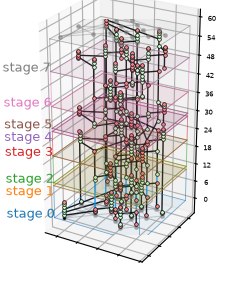

In [4]:
fig = draw_program_3d(p, 0, show_phases=False, spider_size=7, figsize=(3.0, 2.9), space_ticks=False)
ax = fig.axes[0]
ax.set_box_aspect((1, 1, 2.0), zoom=1.25)         # time stretched, so the eight slabs spread out
ax.set_position([0.26, -0.08, 0.72, 1.16])        # fill the figure, with room on the left for the slab names
names = [str(p.stage(s)) for s in range(p.num_stages)]
for label in ax.texts:                            # each slab named by its stage number, left of the slab
    if label.get_text() in names:
        k = names.index(label.get_text())
        label.set_text('stage {}'.format(k))
        label.set_fontsize(9)
        label.set_horizontalalignment('right')
        if k in (1, 4):                           # one-tick stages: the name hangs below, clear of the next one
            label.set_verticalalignment('top')
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_zlabel('')
ax.tick_params(labelsize=5, pad=-2)
fig.savefig('figures/fth-level0-3d.pdf')         # not bbox_inches='tight': it leaves out the 3D text
fig

## Level 1: the protocol's pieces, each with its role

**What we do.** `group_stages(..., one_level=True)` makes level 1 in one go: six blocks, each with a name and a **role**. `summary` answers the three questions for each block and checks the answers against the role:

| role | what `summary` checks |
|---|---|
| encoder | takes the qubit into a larger code; leaves it unchanged |
| transversal gate | one logical gate in every run; its gates connect no two qubits of one code block |
| syndrome extraction | stays in the same code; leaves the qubit unchanged; every result is used or checked again |
| logical gate | one logical gate in every run |
| decoder | takes the qubit out of the code; leaves it unchanged |

In [5]:
GROUPS = [(0, 0, 'encode + round 1', 'encoder'), (1, 1, 'transversal H', 'transversal gate'),
          (2, 3, 'round in code 2', 'syndrome extraction'), (4, 4, 'rotate', 'logical gate'),
          (5, 6, 'round in code 1', 'syndrome extraction'), (7, 7, 'checks + decode', 'decoder')]
L1 = p.group_stages(GROUPS, one_level=True)
print(p.describe_level(L1))

Level 1 (6 blocks):
  Block 0 'encode + round 1' (encoder): [encode + X checks]
  Block 1 'transversal H' (transversal gate): [transversal H]
  Block 2 'round in code 2' (syndrome extraction): [Z checks (code 2), X checks (code 2)]
  Block 3 'rotate' (logical gate): [rotate 90°]
  Block 4 'round in code 1' (syndrome extraction): [Z checks, X checks]
  Block 5 'checks + decode' (decoder): [Z checks + decode]


### Level 1 as one ZX-diagram (panel b)

**What we do.** `draw_program` draws the gates as one ZX-diagram, time going right, shaded by the six blocks of level 1. The axes are made to fill the figure, so `block_spans` gives where each block (and, at level 0, each stage) starts and ends as a fraction of the width: the paper's figure draws its brace, its dotted lines and its dashed links there.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


width / height: 6.448
level 1: where each block starts and ends, as a fraction of the width
  encode + round 1   0.0443 0.1966
  transversal H      0.1966 0.2027
  round in code 2    0.2027 0.3307  0.3307 0.4769
  rotate             0.4769 0.4829
  round in code 1    0.4829 0.6109  0.6109 0.7571
  checks + decode    0.7571 0.9276
level 0: where each block starts and ends, as a fraction of the width
  encode + X checks  0.0443 0.1966
  transversal H      0.1966 0.2027
  Z checks (code 2)  0.2027 0.3307
  X checks (code 2)  0.3307 0.4769
  rotate 90°         0.4769 0.4829
  Z checks           0.4829 0.6109
  X checks           0.6109 0.7571
  Z checks + decode  0.7571 0.9276


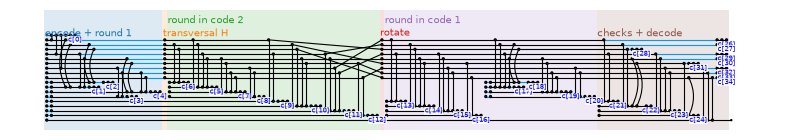

In [6]:
fig = draw_program(p, L1, time_axis=False, show_time=False, even_rows=True, labels_above=True, label_size=5,
                   figsize=(10, 1.6))
ax = fig.axes[0]
x0, x1 = ax.get_xlim()
ax.set_xlim(x0, x1 + 4)                           # room on the right for the names of the last results
ax.set_adjustable('box')                          # the axes take the drawing's shape ...
ax.apply_aspect()
box = ax.get_position()
width, height = fig.get_size_inches()
fig.set_size_inches(box.width * width, box.height * height)
ax.set_position([0, 0, 1, 1])                     # ... and fill the figure, at the same scale
fig.savefig('figures/fth-program.pdf')
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
print("width / height: {:.3f}".format((x1 - x0) / (y1 - y0)))
for level in (L1, 0):
    print("level {}: where each block starts and ends, as a fraction of the width".format(level))
    for label, spans in block_spans(p, level, time_axis=False, even_rows=True):
        print("  {:18s}".format(label), "  ".join("{:.4f} {:.4f}".format((a - x0) / (x1 - x0), (b - x0) / (x1 - x0))
                                                  for a, b in spans))
fig

**What you see.** The 19 wires, time going right, shaded by the six blocks. A blue edge is a Hadamard. The wires that cross, ending at the thin strip *rotate*, are the quarter turn (a wire is drawn from a qubit's last spider to its next one, so it lies over the shading on its left). Every measurement ends in a spider labelled with its result. Each round is two stages, so it has two spans.

In [7]:
print(p.summary(L1))

block               role                 code before  code after  logical action  every run?  checks
0 encode + round 1  encoder              [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 transversal H     transversal gate     [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 round in code 2   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 rotate            logical gate         [[9,1,3]]    [[9,1,3]]   I               yes         ok
4 round in code 1   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
5 checks + decode   decoder              [[9,1,3]]    [[1,1,1]]   I               yes         ok

Block 0 'encode + round 1' (encoder) -- stages 0
  code before: [[1,1,1]] on qubits 0
  code after:  [[9,1,3]] on qubits 1,2,3,4,5,6,7,8,9
  logical action: deterministic up to a Pauli frame: every run implements I followed by a Pauli correction (Z, none) that the outcomes determine
  measurements: 5 (5 frame)
  ok

**What you see.** Every block passes the checks of its role. *transversal H* is a logical H in every run, and it is transversal: no two qubits of one code block are connected. *rotate* moves no state, so by label it ends in the code it started in, with the same logical X and Z. Each round uses or checks every result it measures. *Every run* is up to Paulis that the results determine.

### Question 1 at level 1: the code changes, then comes back

**What we do.** Read the code right after the encoder, after the Hadamards and after the turn (`code_at`), and draw each on the grid (`draw_layout`), with the qubits where they sit on the chip. Then compare them, qubit by qubit and by position (`same_code_as`).

after the encoder:
[[9, 1, 3]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9
    stabilizer (-1)^(c[2])IXXIIIIII
    stabilizer (-1)^(c[3])IIIIIIXXI
    stabilizer (-1)^(c[1])XXIXXIIII
    stabilizer (-1)^(c[4])IIIIXXIXX
    stabilizer +ZIIZIIIII
    stabilizer +IIIIIZIIZ
    stabilizer +ZIIIZIZZI
    stabilizer +IZZIZZIII
    logical X XIIXIIXII   logical Z ZZZIIIIII

after the Hadamards:
[[9, 1, 3]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9
    stabilizer +XIIXIIIII
    stabilizer +IIIIIXIIX
    stabilizer +XIIIXIXXI
    stabilizer +IXXIXXIII
    stabilizer (-1)^(c[2])IZZIIIIII
    stabilizer (-1)^(c[3])IIIIIIZZI
    stabilizer (-1)^(c[1])ZZIZZIIII
    stabilizer (-1)^(c[4])IIIIZZIZZ
    logical X XXXIIIIII   logical Z ZIIZIIZII

after the quarter turn:
[[9, 1, 3]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 (at positions 3, 6, 9, 2, 5, 8, 1, 4, 7)
    stabilizer +XIIXIIIII
    stabilizer +IIIIIXIIX
    stabilizer +XIIIXIXXI
    stabilizer +IXXIXXIII
    stabilizer (-1)^(c[2])IZZI

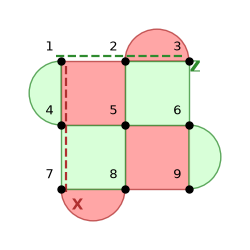

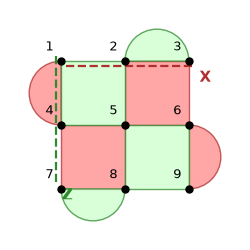

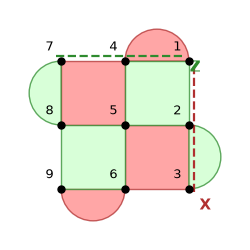

after the Hadamards, the same code as after the encoder: False
after the turn, the same code as after the Hadamards, qubit by qubit: True
after the turn, the same code as after the encoder, by position on the chip: True


In [8]:
coords = {q: p.topology.nodes[q] for q in range(1, 10)}       # the 3x3 grid of data qubits on the chip
pictures = []
for name, stage, file in (('after the encoder', 0, 'code1'), ('after the Hadamards', 1, 'code2'),
                          ('after the quarter turn', 4, 'code3')):
    print(name + ':'); print(p.code_at(stage).data()); print()
    fig = p.code_at(stage).draw_layout(coords, figsize=(2.6, 2.6))
    fig.savefig('figures/fth-{}.pdf'.format(file), bbox_inches='tight')
    pictures.append(fig)
display(*pictures)
print("after the Hadamards, the same code as after the encoder:", p.code_at(1).same_code_as(p.code_at(0)))
print("after the turn, the same code as after the Hadamards, qubit by qubit:", p.code_at(4).same_code_as(p.code_at(1)))
print("after the turn, the same code as after the encoder, by position on the chip:",
      p.code_at(4).same_code_as(p.code_at(0), by='position'))

**What you see.** Red patches are X checks, green patches Z checks, dashed lines the logical X (red) and Z (green). After the Hadamards every check has changed colour: a different [[9,1,3]] code. The turn moves no state, so qubit by qubit the code is still the swapped one; but each qubit now sits elsewhere, and by position it is the surface code again.

### Each block in its normal form (panel c)

**What we do.** Each stage is rewritten into its normal form and drawn on the chip (`draw_blocks_3d`, seen from just off the top), then each picture is saved on its own (`save_panels`). The checks are rewritten with `gpf_checks` (the $Z$ checks with `x-z gpf_checks`): one spider per check, joined to the qubits of that check, with the check's result as its phase. The Hadamards (yellow squares) and the turn are drawn as they are. For these pictures `gpf.build` builds the same program with each qubit (the ancillas and qubit 18) prepared in the stage that first uses it, instead of at the start, so that no picture has idle wires; both builds do the same to the stored qubit, as the last lines check. The figure puts the eight pictures in six columns, one per block of level 1.

Level 1 (8 blocks), rewritten:
  Block 0: encode + X checks (1 children): 62 spiders -> 14 after rewrite gpf_checks
  Block 1: transversal H (1 children): 9 spiders -> 9 after no rewrite
  Block 2: Z checks (code 2) (1 children): 36 spiders -> 22 after rewrite x-z gpf_checks
  Block 3: X checks (code 2) (1 children): 44 spiders -> 22 after rewrite gpf_checks
  Block 4: rotate 90° (1 children): 9 spiders -> 9 after no rewrite
  Block 5: Z checks (1 children): 36 spiders -> 22 after rewrite x-z gpf_checks
  Block 6: X checks (1 children): 44 spiders -> 22 after rewrite gpf_checks
  Block 7: Z checks + decode (1 children): 70 spiders -> 14 after rewrite gpf_checks


panel 0: 2.89 x 1.56 in
panel 1: 1.15 x 1.09 in
panel 2: 1.10 x 1.72 in
panel 3: 1.86 x 1.29 in
panel 4: 1.06 x 1.06 in
panel 5: 1.92 x 1.23 in
panel 6: 1.10 x 1.67 in
panel 7: 1.92 x 1.74 in
this build: 310 spiders; the whole program: deterministic up to a Pauli frame: every run implements H followed by a Pauli correction (X, Y, Z, none) that the outcomes determine
the paper's build: 311 spiders; the whole program: deterministic up to a Pauli frame: every run implements H followed by a Pauli correction (X, Y, Z, none) that the outcomes determine


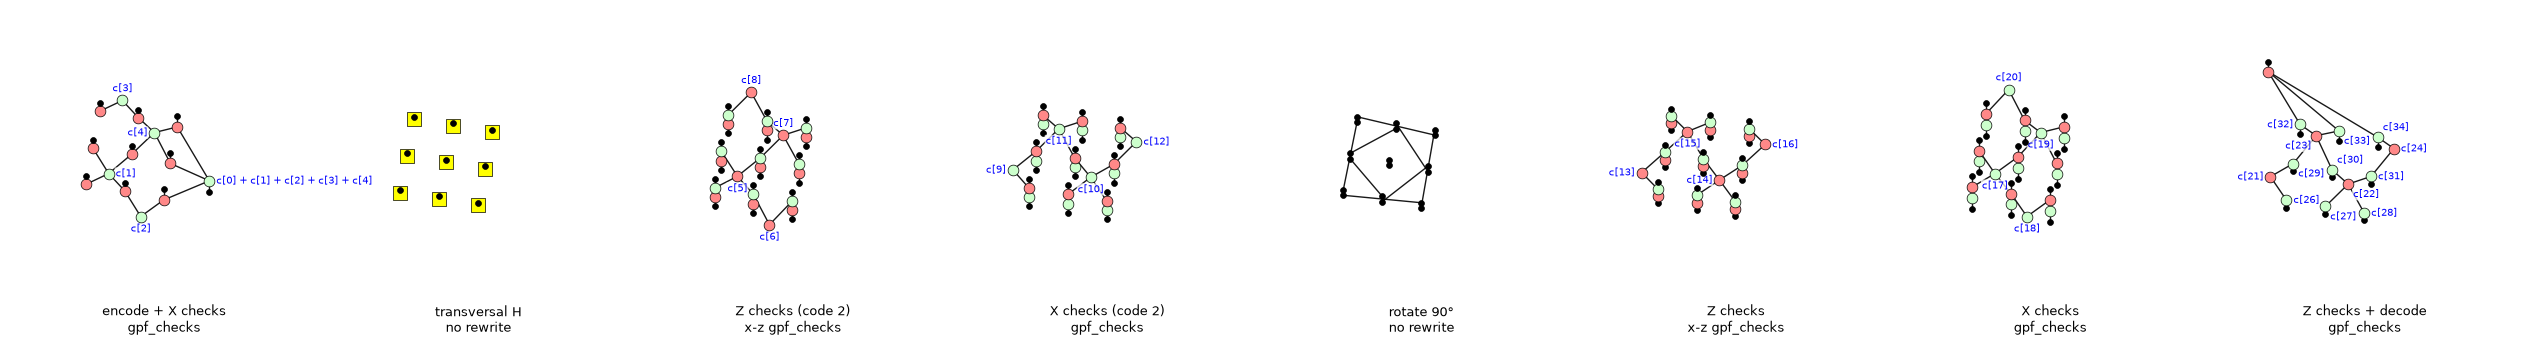

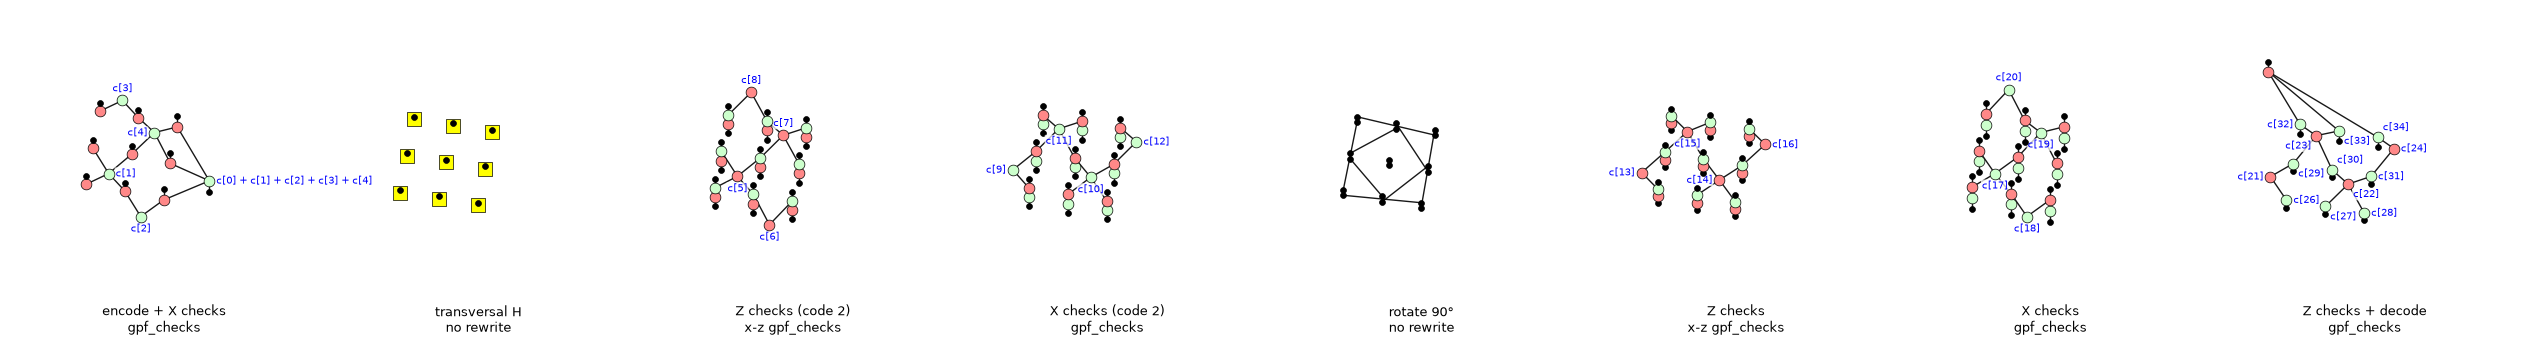

In [9]:
pc, level_c = gpf.build(False, rewrite='gpf_checks', places={0: (4, 2), 14: (0.5, 1.5)})
print(pc.describe_reduced(level_c))
fig = draw_blocks_3d(pc, level_c, view=(70, -80), time_scale=0.5, by_outcomes=True, crossing_wires=True,
                     min_stub=0.25, columns=8, phases_beside=True, hadamard_boxes=True, finish=False)
for k, (w, h) in enumerate(save_panels(fig, 'figures/fth-c-gpf-{k}.{ext}')):
    print("panel {}: {:.2f} x {:.2f} in".format(k, w, h))
for name, program in (("this build", pc), ("the paper's build", p)):
    g = program.quantum_graph()
    print("{}: {} spiders; the whole program: {}".format(
        name, sum(1 for v in g.vertices() if g.type(v) != 0), program.logical_action().verdict()))
fig

**What you see.** From left to right: the encoder with the first round's $X$ checks; the nine Hadamards; the round in code 2, its $Z$ checks above its $X$ checks; the turn; the round in code 1, $Z$ checks above $X$ checks; and the last $Z$ checks with the decoder. Both builds do the same thing to the stored qubit.

## Level 2: the fold-transversal H as one block

**What we do.** `level_up(L1, 1, 3, 'fold-transversal H', 'logical gate', rewrite='gpf')` puts the Hadamards, the round in code 2 and the turn into one block, and rewrites it into its normal form (GPF).

In [10]:
L2 = p.level_up(L1, 1, 3, 'fold-transversal H', 'logical gate', rewrite='gpf')
print(p.summary(L2).table())
print("the checks of block 1:")
for ok, text in p.summary(L2).blocks[1].checks:
    print("  ok     " if ok else "  PROBLEM", text)
print("the code after the block, the same as before it: qubit by qubit", p.code_at(4).same_code_as(p.code_at(0)),
      "; by position on the chip", p.code_at(4).same_code_as(p.code_at(0), by='position'))
print("the same logical X and Z, by position on the chip:", p.code_at(4).same_logicals_as(p.code_at(0), by='position'))
print(p.describe_reduced(L2))

block                 role                 code before  code after  logical action  every run?  checks
0 encode + round 1    encoder              [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 fold-transversal H  logical gate         [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 round in code 1     syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 checks + decode     decoder              [[9,1,3]]    [[1,1,1]]   I               yes         ok
the checks of block 1:
  ok      implements H in every run
  ok      ends in the code it started in, with the same logical X and Z (qubits matched by their place on the chip)


the code after the block, the same as before it: qubit by qubit False ; by position on the chip True
the same logical X and Z, by position on the chip: True
Level 2 (4 blocks), rewritten:
  Block 0: encode + round 1 (1 children): 71 spiders -> 71 after no rewrite
  Block 1: fold-transversal H (3 children): 91 spiders -> 28 after rewrite gpf
  Block 2: round in code 1 (2 children): 80 spiders -> 80 after no rewrite
  Block 3: checks + decode (1 children): 69 spiders -> 69 after no rewrite


**What you see.** The new block is a logical H in every run. `summary` also checks that it ends in the code it started in, with the same logical X and Z, when qubits are matched by where they sit on the chip (`same_code_as`, `same_logicals_as`). By label it is not the same code: there the X and Z checks are swapped. So the block is an H on the surface code, and the change of code and its undoing are inside it. Its rewrite has 28 spiders instead of 91.

### Two wrong requests: one refused, one reported

**What we do.** On a second copy of the program: (1) `merge_blocks` tries to join only the Hadamards and the turn, which are not next to each other; (2) the level-2 block is given the role *transversal gate* instead of *logical gate*.

In [11]:
q = fth.build_program()
Q1 = q.group_stages(GROUPS, one_level=True)
print("merge_blocks(transversal H, rotate):", q.merge_blocks(Q1, 1, 3, 'H + rotate'))
Q2 = q.level_up(Q1, 1, 3, 'fold-transversal H', 'transversal gate')
for ok, text in q.summary(Q2).blocks[1].checks:
    print("ok     " if ok else "PROBLEM", text)

merge_blocks(transversal H, rotate): None


ok      implements H in every run
PROBLEM not transversal: its gates connect qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 of the code block on qubits 1,2,3,4,5,6,7,8,9
ok      ends in the code it started in, with the same logical X and Z (qubits matched by their place on the chip)


**What you see.** (1) `merge_blocks` refuses (`None`): the round between them acts on the same qubits, so the turn cannot be moved next to the Hadamards. (2) The block is a logical H in every run, but it is not transversal: through the ancillas of the round, its gates connect all nine qubits of the grid. At level 1 the Hadamard layer on its own passes this check.

## Level 3: the whole program

**What we do.** `level_up(L2, 0, 3, 'whole program', 'logical gate', rewrite='gpf')`, then `logical_action` on it: what the whole program does to the stored qubit in each run.

block            role          code before  code after  logical action  every run?  checks
0 whole program  logical gate  [[1,1,1]]    [[1,1,1]]   H               yes         ok


Level 3 (1 blocks), rewritten:
  Block 0: whole program (4 children): 248 spiders -> 2 after rewrite gpf; 24 detector(s) removed here
deterministic up to a Pauli frame: every run implements H followed by a Pauli correction (X, Y, Z, none) that the outcomes determine
24 detectors
  when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 0: H, then nothing
  when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 1: H, then Z
  when c[4] + c[0] + c[3] + c[1] + c[2] = 1 and c[29] + c[26] + c[32] = 0: H, then X
  when c[4] + c[0] + c[3] + c[1] + c[2] = 1 and c[29] + c[26] + c[32] = 1: H, then Y


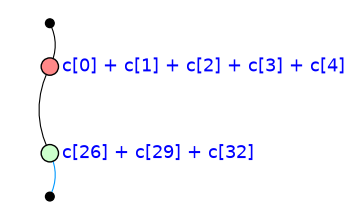

In [12]:
L3 = p.level_up(L2, 0, p.levels.level_size(L2) - 1, 'whole program', 'logical gate', rewrite='gpf')
print(p.summary(L3).table())
print(p.describe_reduced(L3))
action = p.logical_action(L3, 0)
print(action.verdict())
print(len(action.detectors), "detectors")
for b in action.branches():
    print("  {}: {}, then {}".format(b.when(), b.operation, b.correction or 'nothing'))
reduced = p.reduced_block(L3, 0)
up = phases_modulo(reduced.graph, reduced.detectors)
for v in up.vertices():                           # time going up, as in panel (a)
    up.set_qubit(v, -up.row(v))
    up.set_row(v, 0)
fig = draw_graph(up, time_axis=False, show_time=False, label_size=13, label_side='right', figsize=(1.0, 2.6))
fig.savefig('figures/fth-whole-reduced-up.pdf', bbox_inches='tight')
fig

**What you see.** 248 spiders become 2: a Hadamard (the blue edge) on the input, then a green spider with phase $(c_{26}+c_{29}+c_{32})\pi$, a Z when that parity is 1 (the readout of one column of the grid, the logical X: checked below), and a red spider with phase $(c_0+c_1+c_2+c_3+c_4)\pi$, an X when that parity is 1 (the input's measurement and the first round). The results also form 24 detectors, parities that are 0 in every run.

**What we do.** Check where the $Z$ of the Pauli frame comes from: which qubits $c_{26}$, $c_{29}$ and $c_{32}$ read in stage 7, and whether $X$ on those qubits is the logical $X$ of the code before stage 7 (`code_at(6)`), up to its checks (`contains`: is it in the stabilizer group, once multiplied by the logical $X$).

In [13]:
gates = p.stage_circuit(7).gates
reads = {g.result_symbol: (i, g.target) for i, g in enumerate(gates) if isinstance(g, Measurement)}
column = [reads[c][1] for c in ('c[26]', 'c[29]', 'c[32]')]
had_first = all(any(type(g).__name__ == 'HAD' and g.target == q and i < reads[c][0] for i, g in enumerate(gates))
                for c, q in zip(('c[26]', 'c[29]', 'c[32]'), column))
code7 = p.code_at(6).data()                                   # qubits 1..9, the code before stage 7
readout = ''.join('X' if q in column else 'I' for q in range(1, 10))
times_x = ''.join('X' if (a == 'X') != (b == 'X') else 'I' for a, b in zip(readout, code7.logical_x[0].letters))
print("c[26], c[29], c[32] read qubits", column, "; each after an H on it:", had_first)
print(code7)
print("X on those qubits:", readout, "; times the logical X", code7.logical_x[0].letters, "is a check:", code7.contains(times_x))

c[26], c[29], c[32] read qubits [7, 8, 9] ; each after an H on it: True
[[9, 1, 3]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 (at positions 3, 6, 9, 2, 5, 8, 1, 4, 7)
    stabilizer +XIIXIIIII
    stabilizer +IIIIIXIIX
    stabilizer +XIIIXIXXI
    stabilizer +IXXIXXIII
    stabilizer (-1)^(c[2])IZZIIIIII
    stabilizer (-1)^(c[3])IIIIIIZZI
    stabilizer (-1)^(c[1])ZZIZZIIII
    stabilizer (-1)^(c[4])IIIIZZIZZ
    logical X XXXIIIIII   logical Z ZIIZIIZII
X on those qubits: IIIIIIXXX ; times the logical X XXXIIIIII is a check: True


**What you see.** The three results read qubits 7, 8 and 9 in the $X$ basis (an H, then a measurement). These qubits sit at places 1, 4 and 7: the left column of the grid. $X$ on them, times the logical $X$, is in the stabilizer group: so their parity is the logical $X$ of the code.

## The three levels in 3D

**What we do.** `view_levels_3d(..., controls=False)` draws the levels window as a still picture, one per level. Left: the program on the chip, the $3 \times 3$ grid flat and time going up, with the blocks of the level as slabs; the selected block is outlined in bold and the blocks it was made from are dashed. Middle: the program as the level rewrites it, a rewritten block's spiders placed between the ends of its wires. Right: the selected block, cut out of the program, or after its rewrite. Below: what the block is and its size before and after its rewrite. (Run `view_levels_3d(p)` from a terminal or with an interactive backend to get the window with its level slider and buttons.)

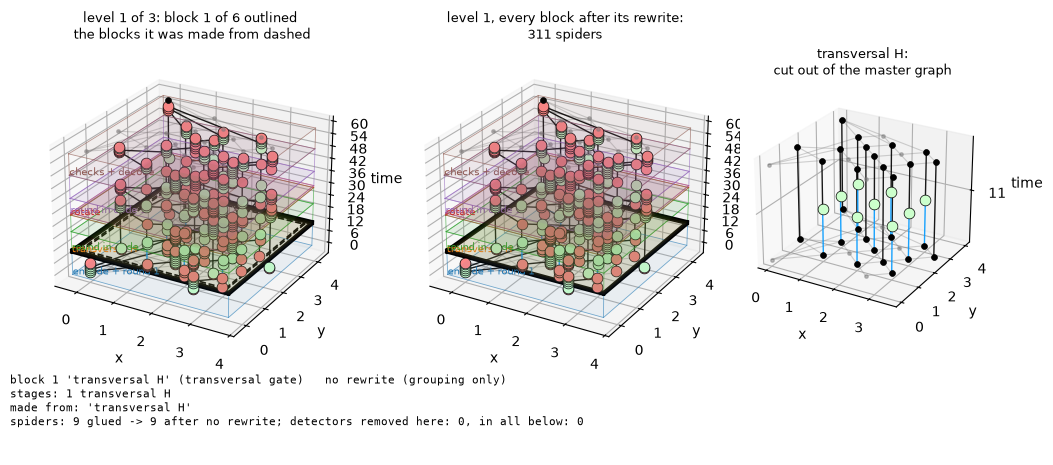

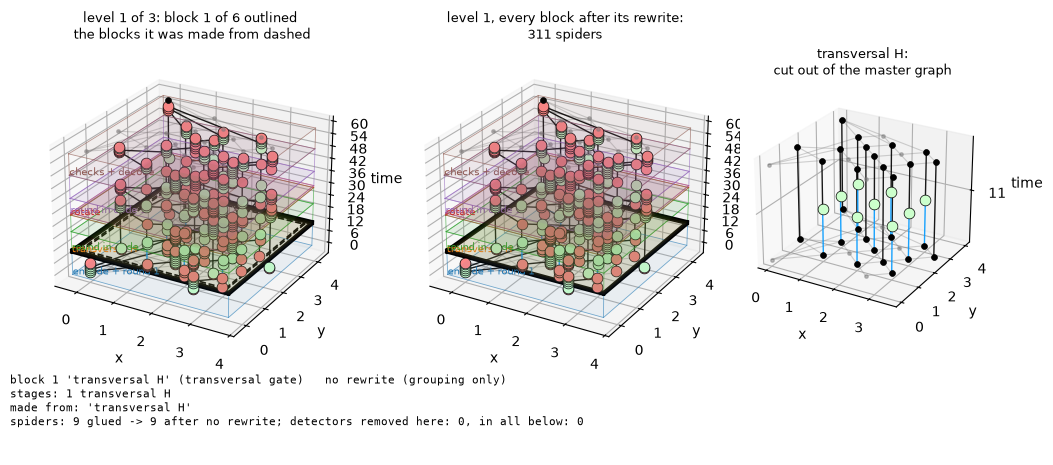

In [14]:
fig = view_levels_3d(p, L1, 1, controls=False, figsize=(10, 4.8), show_phases=False, block_figsize=(3, 4))
fig.savefig('figures/fth-level1.pdf', bbox_inches='tight')
fig

**Level 1.** The six slabs, from the bottom: encode, transversal H, the round in code 2, rotate, the round in code 1, decode. Level 1 has no rewrite, so the middle is the program itself. On the right, the transversal H: nine Hadamards (blue), one on each qubit of the grid, and nothing between them.

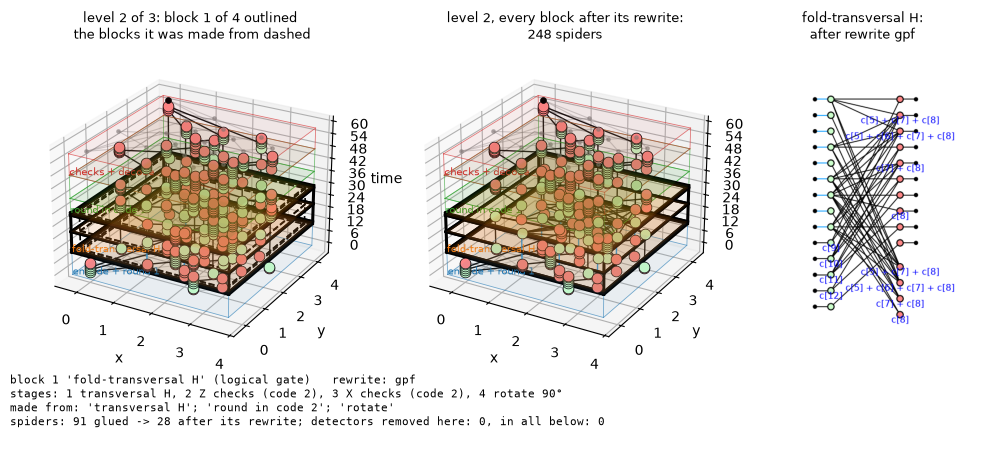

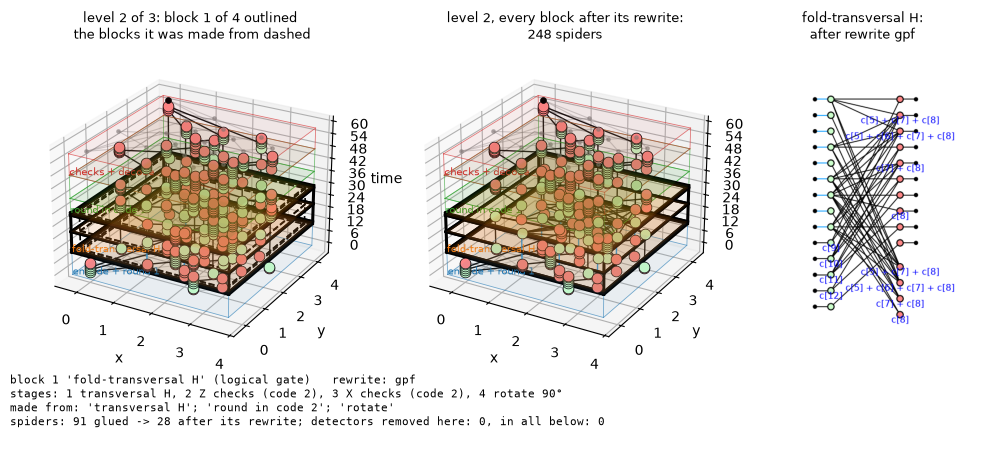

In [15]:
fig = view_levels_3d(p, L2, 1, controls=False, figsize=(10, 4.8), show_phases=False, block_figsize=(3, 4))
fig.savefig('figures/fth-level2.pdf', bbox_inches='tight')
fig

**Level 2.** Left: the block *fold-transversal H* outlined in bold, the three blocks it was made from dashed. Middle: the program with that block replaced by its normal form. Right: the normal form of the block, 28 spiders instead of 91.

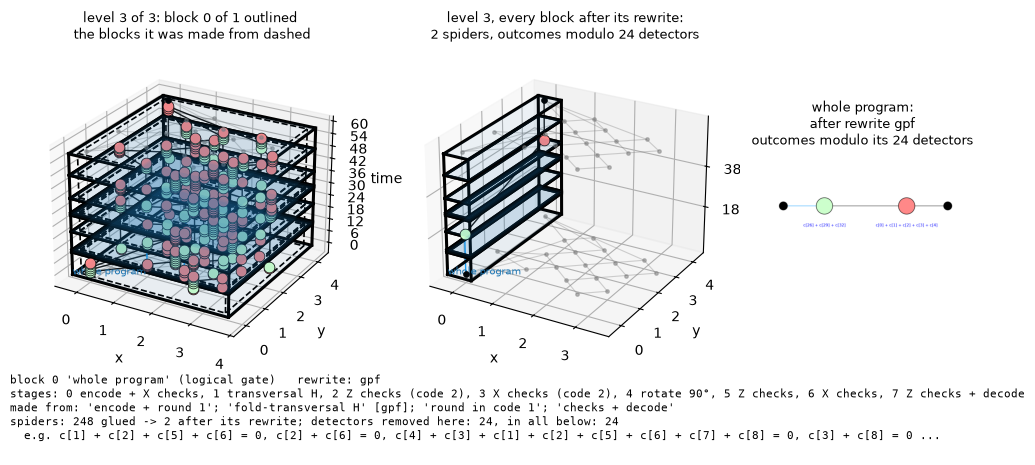

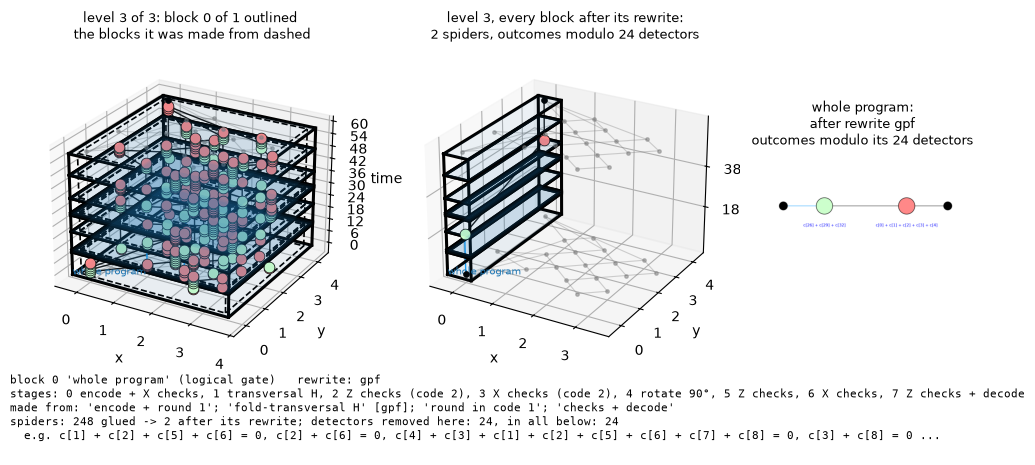

In [16]:
fig = view_levels_3d(p, L3, 0, controls=False, figsize=(10, 4.8), show_phases=False, block_figsize=(7, 3))
fig.savefig('figures/fth-level3.pdf', bbox_inches='tight')
fig

**Level 3.** The whole program is one block. Middle and right: its normal form, two spiders, the Hadamard and the two Paulis of the result above.

## A check on the wrong qubit, level by level

**What we do.** In the file `ft_h_5.qasm`, one Z check of stage 5 used the wrong qubit: `cx q[2], q[14];` where `cx q[4], q[14];` was meant (`build_program(miswired=True)` puts the mistake back). We level it up the same way and read the table at each level.

In [17]:
bad = fth.build_program(miswired=True)
B1 = bad.group_stages(GROUPS, one_level=True)
B2 = bad.level_up(B1, 1, 3, 'fold-transversal H', 'logical gate')
B3 = bad.level_up(B2, 0, bad.levels.level_size(B2) - 1, 'whole program', 'logical gate')
for level in (B1, B2, B3):
    print("level", level); print(bad.summary(level).table()); print()
for ok, text in bad.summary(B1).blocks[4].checks:
    print("ok     " if ok else "PROBLEM", text)
print(len(bad.logical_action(B3, 0).detectors), "detectors for the whole program (24 without the mistake)")
for name, program in (("correct", p), ("mis-wired", bad)):         # the runs with no Pauli correction
    plain = [b for b in program.logical_action().branches() if not b.correction][0]
    print("{}: {}: {}, then nothing".format(name, plain.when(), plain.operation))

level 1


block               role                 code before  code after  logical action  every run?  checks
0 encode + round 1  encoder              [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 transversal H     transversal gate     [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 round in code 2   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 rotate            logical gate         [[9,1,3]]    [[9,1,3]]   I               yes         ok
4 round in code 1   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         1 problem(s)
5 checks + decode   decoder              [[9,1,3]]    [[1,1,1]]   I               yes         ok

level 2
block                 role                 code before  code after  logical action  every run?  checks
0 encode + round 1    encoder              [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 fold-transversal H  logical gate         [[9,1,3]]    [[9,1,3]]   H               yes         

block            role          code before  code after  logical action  every run?  checks
0 whole program  logical gate  [[1,1,1]]    [[1,1,1]]   H               yes         ok



ok      stays in the same code
ok      leaves the logical state unchanged (up to a Pauli frame)
PROBLEM outcome(s) c[13] affect nothing and are never checked again: the circuit may measure an operator that is not a stabilizer of the code
22 detectors for the whole program (24 without the mistake)
correct: when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 0: H, then nothing
mis-wired: when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[18] + c[32] = 0: H, then nothing


**Level 0 on the mis-wired program.** The stages have no roles here, so no role check runs; but the code column shows where the code breaks:

In [18]:
print(bad.summary(0).table())

block                role  code before  code after  logical action  every run?  checks
0 encode + X checks  -     [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 transversal H      -     [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 Z checks (code 2)  -     [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 X checks (code 2)  -     [[9,1,3]]    [[9,1,3]]   I               yes         ok
4 rotate 90°         -     [[9,1,3]]    [[9,1,3]]   I               yes         ok
5 Z checks           -     [[9,1,3]]    [[9,1,1]]   I               yes         ok
6 X checks           -     [[9,1,1]]    [[9,1,3]]   I               yes         ok
7 Z checks + decode  -     [[9,1,3]]    [[1,1,1]]   I               yes         ok


**What you see.** Levels 1 and 2 flag the block *round in code 1*: its result `c[13]` affects nothing and is never checked again. Level 3 says H, ok: the whole program still does the right thing when nothing goes wrong. With every result 0 both programs are H, then nothing, so a check that sets every result to 0 cannot see the mistake either. The mistake shows only from a lower level, where each round is checked against its role.

**What it costs.** The code right after stage 5, as Question 1 reads it:

[[9, 1, 1]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 (at positions 3, 6, 9, 2, 5, 8, 1, 4, 7)
    stabilizer +IIIIIXIIX
    stabilizer +IXXIXXIII
    stabilizer +IIIXXIXXI
    stabilizer (-1)^(c[2])IZZIIIIII
    stabilizer (-1)^(c[13])IIIZIIZII
    stabilizer (-1)^(c[3])IIIIIIZZI
    stabilizer (-1)^(c[1])ZZIZZIIII
    stabilizer (-1)^(c[4])IIIIZZIZZ
    logical X XXXIIIIII   logical Z ZIIIIIIII


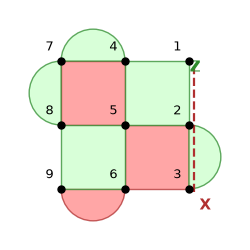

In [19]:
print(bad.code_at(5).data())
fig = bad.code_at(5).draw_layout(coords, figsize=(2.6, 2.6))
fig.savefig('figures/fth-miswired-code.pdf', bbox_inches='tight')
fig

**What you see.** A [[9,1,1]] code: distance 1. The wrong check measures Z on chip qubits 1 and 2 (the green half disc on the left of the top edge); the X check on chip qubits 2 and 3 is gone; the logical Z is a Z on one qubit, in the top right corner. So one error there can change the stored qubit without any check seeing it. We put one Z error on that qubit right after the stage (`z_error=3`):

In [20]:
for miswired in (False, True):
    clean = fth.build_program(miswired=miswired).logical_action()
    hit = fth.build_program(miswired=miswired, z_error=3).logical_action()
    changed = sorted(set(map(str, hit.detectors)) - set(map(str, clean.detectors)))
    print("mis-wired:" if miswired else "correct:", len(hit.detectors), "detectors; with the error they read",
          ", ".join(d + " = 0" for d in changed) if changed else "the same as without it")
    print("   Z correction without the error:", [b.when() for b in clean.branches() if b.correction == 'Z'][0])
    print("   Z correction with the error:   ", [b.when() for b in hit.branches() if b.correction == 'Z'][0])

correct: 24 detectors; with the error they read c[18] + 1 = 0, c[28] + 1 + c[27] = 0
   Z correction without the error: when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 1
   Z correction with the error:    when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 1


mis-wired: 22 detectors; with the error they read the same as without it
   Z correction without the error: when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[18] + c[32] = 1
   Z correction with the error:    when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and 1 + c[29] + c[26] + c[18] + c[32] = 1


**What you see.** In the correct program two detectors now read 1 ($c_{18}$, and $c_{27}+c_{28}$): the error is caught. In the mis-wired one the detectors do not change, and the condition for the Z correction flips: every run ends with an extra logical Z.